# 03 - Which model catches fake job ads most usefully?

Compare the existing text-only logistic-regression model with A2 logistic regression, LightGBM and XGBoost.

Every model scores the **same ads in the same 25 rounds**: five groups of tests, repeated five times. Related ads always stay together. Each round chooses its settings and flagging cutoff using three smaller splits of that round's training ads. It then scores ads it has not seen. **The reserved final test file is never opened.**

Questions to answer:
1. Of the fake ads, how many does the model catch?
2. How many genuine ads does it wrongly flag?
3. If reviewers can read only the highest-scoring 5% of ads, how useful is that shortlist?
4. Does an improvement hold across repeats, and is the uncertainty small enough to support the claim?

A2 adds the original job fields, missing/contact/salary features and writing-style features. The three A2 models use identical features and a 2,000-term text limit. The existing text-only reference retains its 30,000-term limit. Compare the tree models with A2 logistic regression to isolate the change in model with matching inputs.

## 1. Run once, then inspect the saved results

The full experiment can take a while. Keep `RUN_COMPARISON=False` to read completed results. To run from a terminal, use:

```powershell
.\.venv\Scripts\python.exe -u -m src.model_comparison
```

Completed models are reused when the data, code and settings match. Per-round checkpoints show progress. A partially completed model is restarted if the process is interrupted. Completed results belong in `reports/model_comparison/`; row-level predictions stay in the ignored processed-data folder.

In [1]:
import json
from pathlib import Path
import subprocess
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src' / 'model_comparison.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the project.')
sys.path.insert(0, str(ROOT))
from src.model_comparison import MODEL_KEYS, MODEL_NAMES

REPORT_DIR = ROOT / 'reports' / 'model_comparison'
RUN_COMPARISON = False
if RUN_COMPARISON:
    subprocess.run([sys.executable, '-u', '-m', 'src.model_comparison'], cwd=ROOT, check=True)
missing = [key for key in MODEL_KEYS if not (REPORT_DIR / f'{key}_complete.json').exists()]
if missing:
    raise FileNotFoundError(f'Comparison is not complete yet. Missing models: {missing}. Run the command above first.')
plan = json.loads((REPORT_DIR / 'run_plan.json').read_text(encoding='utf-8'))
summary = pd.read_csv(REPORT_DIR / 'comparison_summary.csv', index_col='model')
repeats = pd.read_csv(REPORT_DIR / 'results_by_repeat.csv')
paired = pd.read_csv(REPORT_DIR / 'paired_differences.csv')
print(f"{plan['training_rows']:,} ads: {plan['fraud_rows']} fake and {plan['genuine_rows']:,} genuine.")
print(f"{plan['repeats']} repeats x {plan['splits']} test rounds per model; {plan['inner_splits']} smaller training splits per round.")
print('The separate final test set has not been used.')

14,439 ads: 693 fake and 13,746 genuine.
5 repeats x 5 test rounds per model; 3 smaller training splits per round.
The separate final test set has not been used.


## 2. What happens to the same set of ads?

The ordinary flagging cutoff is chosen to balance catching fraud and avoiding false alarms, using training ads only. Counts below are **averages across the five repeats**. In each repeat, every training ad is scored once.

The 5% review results are a **different policy**: reviewers take the highest-scoring 5% within each held-aside batch, regardless of the ordinary cutoff. The percentage is rounded down to a whole number of ads in each batch.

The repeats reuse the same ads, so do not add the counts together as though they were five independent datasets.

,Fake ads caught (of 693),Genuine ads wrongly flagged (of 13746),Flags that are fake,Fake ads found in 5% review,5% review: flags that are fake,Mean PR-AUC
Logistic regression: text only,352.0,308.4,53.5%,377.6,52.4%,0.595
Logistic regression: A2,376.8,443.2,46.8%,370.8,51.5%,0.555
LightGBM: A2,383.6,414.4,49.1%,389.0,54.0%,0.631
XGBoost: A2,336.6,398.0,46.0%,344.8,47.9%,0.566


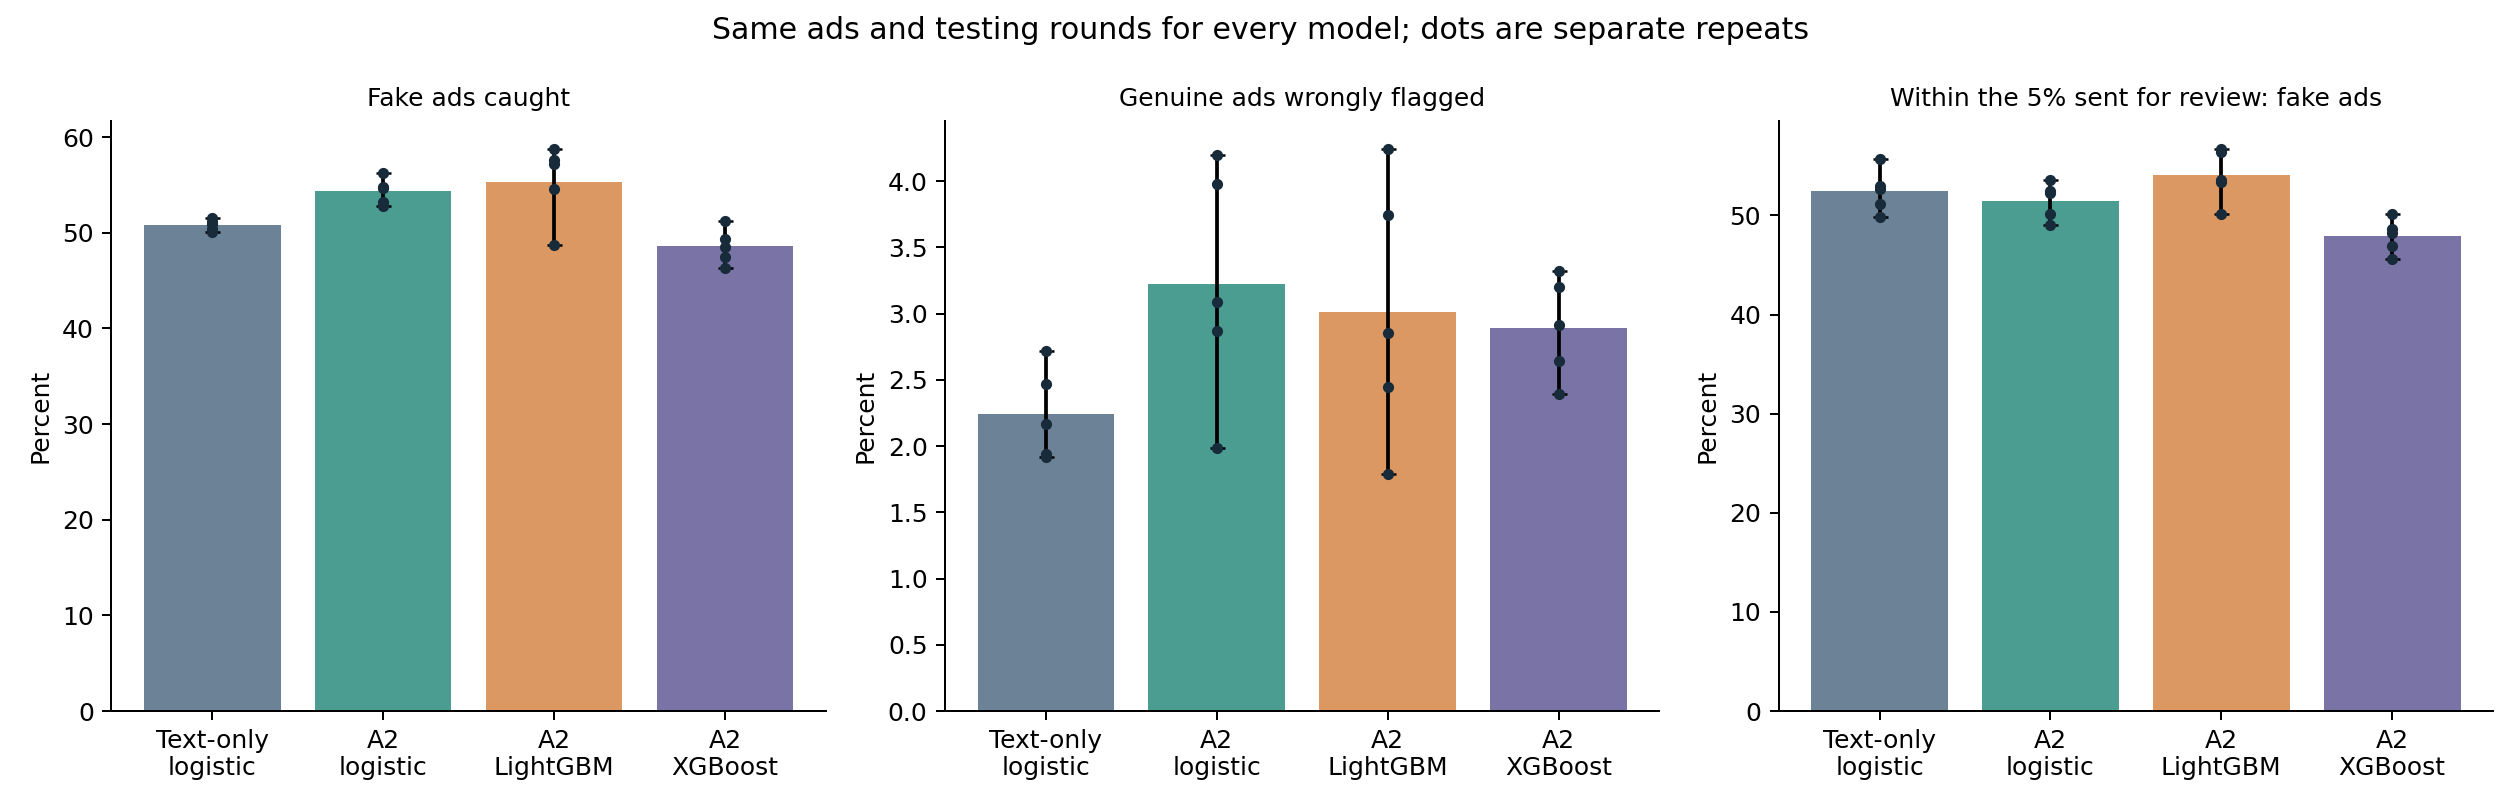

Dots show the individual repeats. Error bars show their range, not a confidence interval.


In [2]:
friendly = pd.read_csv(REPORT_DIR / 'plain_language_summary.csv', index_col=0)
display(friendly)
display(Image(filename=str(REPORT_DIR / 'comparison.png')))
print('Dots show the individual repeats. Error bars show their range, not a confidence interval.')

## 3. Is the pattern consistent across repeats?

Check whether a model catches more fraud only by creating more false alarms. The last two columns describe what happens when the review workload is held at about 5%.

In [3]:
by_repeat = repeats[['model', 'repeat', 'fraud_caught', 'genuine_flagged', 'recall',
                     'false_positive_rate', 'review_count', 'review_fraud_caught',
                     'review_precision', 'review_recall', 'mean_fold_pr_auc']].copy()
by_repeat['model'] = by_repeat['model'].map(MODEL_NAMES)
by_repeat['repeat'] += 1
display(by_repeat.round(3))

,model,repeat,fraud_caught,genuine_flagged,recall,false_positive_rate,review_count,review_fraud_caught,review_precision,review_recall,mean_fold_pr_auc
0,Logistic regression: text only,1,347,339,0.501,0.025,720,379,0.526,0.547,0.593
1,Logistic regression: text only,2,354,374,0.511,0.027,720,401,0.557,0.579,0.628
2,Logistic regression: text only,3,349,298,0.504,0.022,720,359,0.499,0.518,0.575
3,Logistic regression: text only,4,353,264,0.509,0.019,720,381,0.529,0.550,0.608
4,Logistic regression: text only,5,357,267,0.515,0.019,720,368,0.511,0.531,0.568
5,Logistic regression: A2,1,369,547,0.532,0.040,720,376,0.522,0.543,0.556
6,Logistic regression: A2,2,390,577,0.563,0.042,720,378,0.525,0.545,0.580
7,Logistic regression: A2,3,380,425,0.548,0.031,720,361,0.501,0.521,0.527
8,Logistic regression: A2,4,379,273,0.547,0.020,720,386,0.536,0.557,0.568
9,Logistic regression: A2,5,366,394,0.528,0.029,720,353,0.490,0.509,0.545


## 4. Is a ranking improvement clear enough to trust?

PR-AUC measures how well fake ads are ranked ahead of genuine ads over many possible cutoffs. It is not the percentage of ads classified correctly.

The difference below is **candidate minus reference**. A positive PR-AUC difference favours the candidate. If its interval crosses zero, these tests do not clearly establish a ranking improvement. The intervals account approximately for overlap in training data; they are exploratory and are not adjusted for every comparison.

A better ranking does not automatically mean fewer false alarms at the selected cutoff. The other rows in `paired_differences.csv` compare fraud caught, false-alarm rates and the 5% review results.

,model,mean_diff,low,high,share_folds_a_better
0,Logistic regression: A2,-0.039,-0.137,0.058,0.28
5,LightGBM: A2,0.037,-0.051,0.124,0.68
10,XGBoost: A2,-0.029,-0.119,0.061,0.40


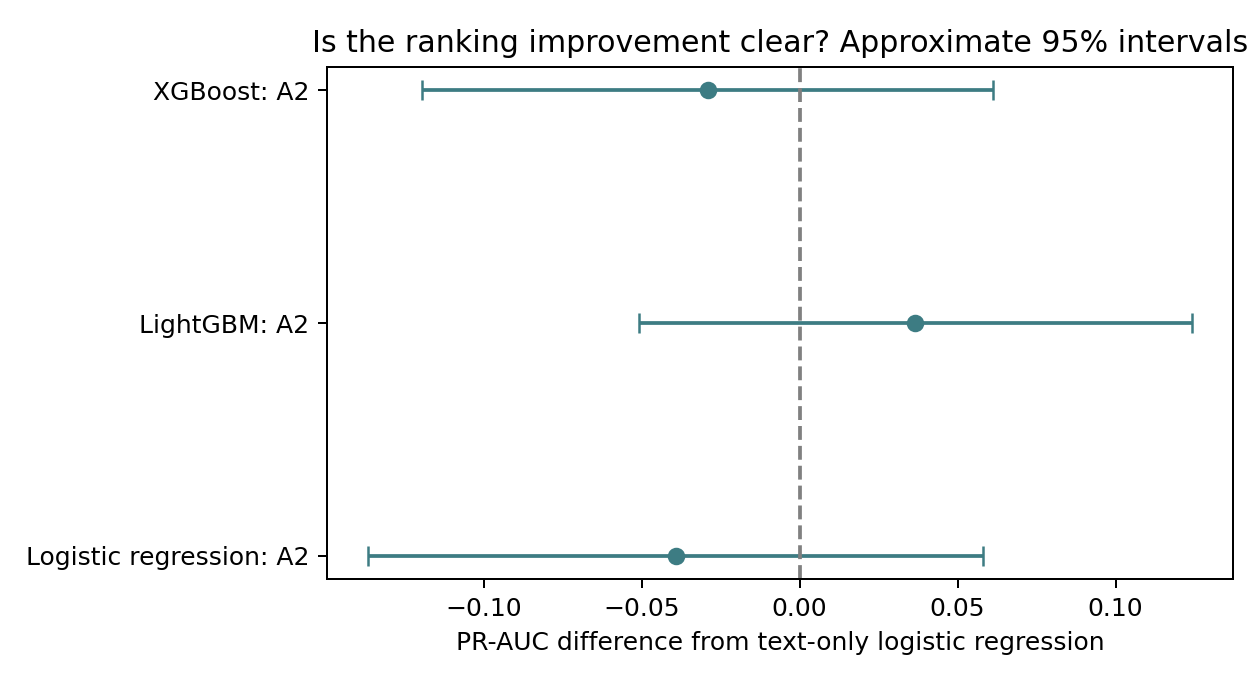

Same-feature comparison against A2 logistic regression:


,model,metric,mean_diff,low,high,share_folds_a_better
20,lightgbm_a2,pr_auc,0.076,-0.013,0.165,0.84
21,lightgbm_a2,recall,0.013,-0.087,0.114,0.52
22,lightgbm_a2,false_positive_rate,-0.002,-0.029,0.025,0.56
23,lightgbm_a2,precision_top5pct,0.024,-0.055,0.102,0.64
24,lightgbm_a2,recall_top5pct,0.032,-0.048,0.112,0.64
25,xgboost_a2,pr_auc,0.010,-0.099,0.119,0.52
26,xgboost_a2,recall,-0.053,-0.140,0.035,0.24
27,xgboost_a2,false_positive_rate,-0.002,-0.033,0.029,0.44
28,xgboost_a2,precision_top5pct,-0.040,-0.130,0.051,0.28
29,xgboost_a2,recall_top5pct,-0.030,-0.119,0.059,0.28


In [4]:
rank_comparison = paired[(paired['reference'] == 'logreg_tfidf') & (paired['metric'] == 'pr_auc')].copy()
rank_comparison['model'] = rank_comparison['model'].map(MODEL_NAMES)
display(rank_comparison[['model', 'mean_diff', 'low', 'high', 'share_folds_a_better']].round(3))
display(Image(filename=str(REPORT_DIR / 'paired_uncertainty.png')))
print('Same-feature comparison against A2 logistic regression:')
matched = paired[(paired['reference'] == 'logreg_a2') & paired['model'].isin(['lightgbm_a2','xgboost_a2'])]
display(matched[['model','metric','mean_diff','low','high','share_folds_a_better']].round(3))

## 5. Read the results in plain language

These statements describe the completed training-data tests. They do not choose a final model or use the reserved test set. Check whether the extra scams caught justify the extra genuine ads flagged for your intended review workload.

In [5]:
for key in MODEL_KEYS:
    row = summary.loc[key]
    print(f"{MODEL_NAMES[key]}: catches {row['fraud_caught']:.1f} of {plan['fraud_rows']} fake ads "
          f"({row['recall']:.1%}), while wrongly flagging {row['genuine_flagged']:.1f} genuine ads "
          f"({row['false_positive_rate']:.1%} of genuine ads).")
    print(f"  With only 5% reviewed: {row['review_fraud_caught']:.1f} fake ads found; "
          f"{row['review_precision']:.1%} of reviewed ads are fake.")
    if key != 'logreg_tfidf':
        interval = paired[(paired['model']==key) & (paired['reference']=='logreg_tfidf') & (paired['metric']=='pr_auc')].iloc[0]
        if interval['low'] > 0:
            print('  These tests support better ranking than the text-only reference.')
        elif interval['high'] < 0:
            print('  These tests support worse ranking than the text-only reference.')
        else:
            print('  These tests do not clearly establish a ranking difference from the text-only reference.')
    print()

Logistic regression: text only: catches 352.0 of 693 fake ads (50.8%), while wrongly flagging 308.4 genuine ads (2.2% of genuine ads).
  With only 5% reviewed: 377.6 fake ads found; 52.4% of reviewed ads are fake.

Logistic regression: A2: catches 376.8 of 693 fake ads (54.4%), while wrongly flagging 443.2 genuine ads (3.2% of genuine ads).
  With only 5% reviewed: 370.8 fake ads found; 51.5% of reviewed ads are fake.
  These tests do not clearly establish a ranking difference from the text-only reference.

LightGBM: A2: catches 383.6 of 693 fake ads (55.4%), while wrongly flagging 414.4 genuine ads (3.0% of genuine ads).
  With only 5% reviewed: 389.0 fake ads found; 54.0% of reviewed ads are fake.
  These tests do not clearly establish a ranking difference from the text-only reference.

XGBoost: A2: catches 336.6 of 693 fake ads (48.6%), while wrongly flagging 398.0 genuine ads (2.9% of genuine ads).
  With only 5% reviewed: 344.8 fake ads found; 47.9% of reviewed ads are fake.
  The

## Files for checking or reporting the work

- `reports/model_comparison/report.html`: standalone report with tables and figures.
- `comparison_summary.csv`: average outcomes across repeats.
- `results_by_repeat.csv`: counts and rates for each repeat.
- `paired_differences.csv`: approximate paired uncertainty for each metric.
- `repeat_differences_vs_baseline.csv`: changes relative to the reference in each repeat.
- `*_fold_scores.csv`, `*_inner_settings.csv`: round-by-round results and the settings tried.
- `run_plan.json`, `fold_plan.csv`: exact run settings, package versions, data/code fingerprints and test-round identities.
- `data/processed/model_comparison/`: exact row assignments and predictions, ignored by Git.

The next decision is which tradeoff is useful enough to take forward. Keep the final test file reserved until that decision and the final model settings have been fixed.